# Week 5 — End-to-End Insider Threat Detection Pipeline

**Reproducibility & demonstration notebook** for the finalized Week-5 system.
This notebook is a *presentation layer*: it consumes the existing `week5/final_pipeline/*.py`
implementation and the existing verified artifacts. It does **not** re-implement the pipeline.

```
CERT r4.2 held-out test data
        ↓
Tier 1 — HTTP / File-Device / Logon / Email
        ↓
Tier 2 — LangGraph validated fusion
        ↓
Escalated cases
        ↓
Week-4 EvidenceBuilder
        ↓
Tier 3 — Qwen2.5-1.5B-Instruct
        ↓
Grounding / schema validation
        ↓
FastAPI service
```

Key facts:

* **Tier 2 makes the security escalation decision** (frozen gating: HC = 0.60, correlation = 0.30, weights 50/20/15/15).
* **Tier 3 reasons only about escalated cases** — it does not make the escalation decision and has no manual severity/action policy.
* **Week 1–4 source files are consumed unchanged** (frozen Tier-1 models, frozen Tier-2 inputs, frozen Week-4 Tier-3 outputs).
* Week 5 uses the **frozen final configuration** — nothing is retrained or re-tuned here.

## Section 2 — Environment and Reproducibility

Actual runtime versions and the key data/artifact paths. The notebook must run even when
Ollama is unavailable (frozen Week-4 Tier-3 outputs remain usable for evaluation).

In [1]:
import sys, platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import sklearn
import fastapi
import mlflow

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for _p in (str(ROOT), str(ROOT / "week5"), str(ROOT / "week4" / "final_llm_reasoning")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import importlib
versions = {}
for m in ("langgraph", "shap", "ollama"):
    try:
        mod = importlib.import_module(m)
        versions[m] = getattr(mod, "__version__", "available")
    except Exception:
        versions[m] = "not installed"

env = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "pytorch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "fastapi": fastapi.__version__,
    "mlflow": mlflow.__version__,
    "langgraph": versions["langgraph"],
    "shap": versions["shap"],
    "ollama": versions["ollama"],
}
pd.Series(env, name="version").to_frame().T

,python,platform,pytorch,numpy,pandas,scikit_learn,fastapi,mlflow,langgraph,shap,ollama
version,3.12.13,Windows-11-10.0.26200-SP0,2.5.1+cu121,2.5.1,2.3.3,1.9.0,0.139.2,3.14.0,available,not installed,available


In [2]:
from week5.final_pipeline import pipeline as P

# Ollama availability + Qwen model (frozen Week-4 LLM)
try:
    import ollama
    models = ollama.list().models
    qwen = next((m.model for m in models if "qwen2.5" in getattr(m, "model", "")), None)
    ollama_ok = qwen is not None
except Exception:
    qwen, ollama_ok = None, False

print(f"Ollama available: {ollama_ok}")
print(f"Qwen model: {qwen if ollama_ok else P.LLM_MODEL + ' (frozen config; not reachable)'}")
if not ollama_ok:
    print("Ollama unavailable — live Tier-3 demonstration skipped.")
    print("Frozen Week-4 Tier-3 outputs remain available for evaluation.")

paths = {
    "Tier-1 artifacts": str(P.TIER1_DIR),
    "Frozen Tier-2 input": str(P.W4_FROZEN_INPUT),
    "Week-4 Tier-3 outputs": str(P.W4_TRIAGE_OUTPUTS),
    "Week-4 grounding results": str(P.W4_GROUNDING_RESULTS),
    "Week-5 outputs": str(P.OUT),
}
pd.Series(paths, name="path").to_frame().T

Ollama available: True
Qwen model: qwen2.5:1.5b-instruct


C:\insider_threat_detection_project2\.venv\Lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5090 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5090 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


,Tier-1 artifacts,Frozen Tier-2 input,Week-4 Tier-3 outputs,Week-4 grounding results,Week-5 outputs
path,C:\insider_threat_detection_project2\tier1,C:\insider_threat_detection_project2\week4\fro...,C:\insider_threat_detection_project2\week4\fin...,C:\insider_threat_detection_project2\week4\fin...,C:\insider_threat_detection_project2\week5\fin...


## Section 3 — Frozen Configuration

The frozen Tier-2 configuration is read from the implementation (not typed by hand) and
verified programmatically. If the implementation differed, this cell would report it.

In [3]:
cfg = {
    "HC threshold": P.HC_THRESHOLD,
    "Correlation threshold": P.CORR_THRESHOLD,
    **{f"Weight {k}": v for k, v in P.WEIGHTS.items()},
}
pd.Series(cfg, name="value").to_frame()

expected = {"HC threshold": 0.60, "Correlation threshold": 0.30,
            "Weight http": 0.50, "Weight file_device": 0.20,
            "Weight logon": 0.15, "Weight email": 0.15}
assert all(abs(cfg[k] - expected[k]) < 1e-9 for k in expected), "Frozen config mismatch!"
print("Frozen configuration verified: HC=0.60, corr=0.30, weights 50/20/15/15.")

Frozen configuration verified: HC=0.60, corr=0.30, weights 50/20/15/15.


## Section 4 — Final Architecture

```
                    CERT r4.2
                       │
                       ▼
              ┌─────────────────┐
              │     Tier 1      │
              │ HTTP / File-Device / Logon / Email (frozen MLPs)
              └────────┬────────┘
                       │  per-modality anomaly scores
                       ▼
              ┌─────────────────┐
              │     Tier 2      │
              │    LangGraph    │
              │ Fusion + Gates  │  ← escalation decision (HC 0.60 / corr 0.30)
              └────────┬────────┘
                       │
                Escalated cases (712)
                       │
                       ▼
              ┌─────────────────┐
              │ EvidenceBuilder │  ← canonical Week-4 evidence inventory
              └────────┬────────┘
                       │
                       ▼
              ┌─────────────────┐
              │      Tier 3     │
              │ Qwen2.5-1.5B    │  ← reasons only about escalated cases
              └────────┬────────┘
                       │
                       ▼
              ┌─────────────────┐
              │ Grounding /     │
              │ Schema Validation│
              └────────┬────────┘
                       │
                       ▼
                 FastAPI /score
```

The pipeline is fully modular: `tier1.py` (Tier-1 agents), `tier2.py` (LangGraph
fusion + gates), `tier3.py` (canonical Week-4 Tier-3), `app.py` (FastAPI service).

## Section 5 — Frozen Test Dataset and Leakage Verification

Loads the frozen held-out test split and verifies user-set disjointness (train ∩ val,
train ∩ test, val ∩ test = ∅) from the actual Tier-1 metadata. All counts are derived
from the files, not hard-coded.

In [4]:
import json

t2 = pd.read_csv(P.W4_FROZEN_INPUT)
escalated = t2[t2["escalate"] == 1]
print(f"Frozen Tier-2 input rows: {len(t2):,}   escalated: {len(escalated):,}   "
      f"positive user-days: {int(t2['label'].sum()):,}")

meta = {m: json.loads((P.TIER1_DIR / m / "meta.json").read_text())
        for m in ("http", "file_device", "logon", "email")}
train_u = set(meta["http"]["train_users"]); val_u = set(meta["http"]["validation_users"]); test_u = set(meta["http"]["test_users"])
for m in ("file_device", "logon", "email"):
    train_u &= set(meta[m]["train_users"]); val_u &= set(meta[m]["validation_users"]); test_u &= set(meta[m]["test_users"])

split = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "users": [len(train_u), len(val_u), len(test_u)],
    "users_per_modality": [600, 200, 200],
})
split

leak = {
    "train ∩ validation": len(train_u & val_u),
    "train ∩ test": len(train_u & test_u),
    "validation ∩ test": len(val_u & test_u),
}
leak_df = pd.Series(leak, name="count").to_frame()
leak_df["disjoint"] = leak_df["count"] == 0
leak_df

Frozen Tier-2 input rows: 61,203   escalated: 712   positive user-days: 201


,count,disjoint
train ∩ validation,0,True
train ∩ test,0,True
validation ∩ test,0,True


In [5]:
leak_pass = all(v == 0 for v in list(leak.values()))
print(f"Leakage checks PASS (all intersections empty): {leak_pass}")
assert leak_pass, "User-set overlap detected!"
print(f"Test split: {t2['user'].nunique()} users / {len(t2):,} rows / "
      f"{int(t2['label'].sum()):,} positive user-days / {len(escalated):,} escalated.")

Leakage checks PASS (all intersections empty): True
Test split: 200 users / 61,203 rows / 201 positive user-days / 712 escalated.


## Section 6 — Tier 1 Demonstration

**Frozen Tier-1 artifacts are loaded; no retraining is performed.**

The existing `tier1.py` assembles the raw percentile feature rows (in the model's exact
feature order) and scores them with the frozen MLPs. Feature order, scaler dimensions and
model input dimensions are verified against `meta.json`.

In [6]:
from week5.final_pipeline import pipeline as P
from week5.final_pipeline import tier1 as T1

bundle = P.load_tier1()

# structural verification: feature order / scaler / model dims
dims = []
for mod in P.CHANNELS:
    meta = bundle["meta"][mod]
    dims.append({
        "modality": mod,
        "model_input_dim": bundle["models"][mod].net[0].in_features,
        "meta_input_dim": meta["input_dim"],
        "scaler_mean_len": len(bundle["scalers"][mod].mean_),
        "feature_cols": len(bundle["feature_cols"][mod]),
        "seed": meta["seed"],
    })
dim_df = pd.DataFrame(dims)
dim_df
assert (dim_df["model_input_dim"] == dim_df["meta_input_dim"]).all()
assert (dim_df["scaler_mean_len"] == dim_df["feature_cols"]).all()
print("Tier-1 structure verified (feature order = model order, dims aligned).")

Tier-1 structure verified (feature order = model order, dims aligned).


In [7]:
# one representative held-out test case (first escalated row)
test_pkl = pd.read_pickle(str(P.DATA_DIR / "dayr4.2-percentile30-test.pkl"))
row = escalated.iloc[0]
case = pd.DataFrame({"user": [int(row["user"])], "day": [int(row["day"])]})
feats = T1.assemble_feature_rows(test_pkl, case, bundle)
scores = T1.score_cases(bundle, feats)

s = scores.iloc[0]
pd.DataFrame({
    "modality": P.CHANNELS,
    "score": [s[f"{m}_score"] for m in P.CHANNELS],
    "feature_dim": [len(s[f"{m}_features"]) for m in P.CHANNELS],
})

C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,modality,score,feature_dim
0,http,0.934825,204
1,file_device,0.007847,215
2,logon,0.076195,20
3,email,0.214648,47


## Section 7 — Tier 2 / LangGraph Demonstration

**Tier 2 is responsible for the validated security escalation decision.**

The existing `tier2.py` LangGraph orchestrator runs the frozen sequential gates on one
representative case. No new decision rule is introduced here.

In [8]:
from week5.final_pipeline import tier2 as T2

# run the real LangGraph orchestrator on the same representative case
lg = T2.graph_decision(scores.iloc[0])
pd.DataFrame({
    "fused_score": round(float(lg["risk_score"]), 4),
    "fired_channels": lg["fired_channels"],
    "gate": lg["gate_triggered"],
    "escalated": bool(lg["escalate"]),
    "degraded_channels": lg.get("degraded_channels", []),
    "degraded_mode": bool(lg.get("degraded_mode", False)),
    "rationale": lg["rationale"],
}.items(), columns=["field", "value"])

,field,value
0,fused_score,0.5126
1,fired_channels,[http]
2,gate,high_confidence
3,escalated,True
4,degraded_channels,[]
5,degraded_mode,False
6,rationale,HIGH-CONFIDENCE ESCALATION: HTTP anomaly score...


## Section 8 — LangGraph vs Vectorized Equivalence

The real LangGraph orchestrator is compared against the vectorized reference
implementation over the actual test population. The result (expected: 0 mismatches) is
derived from execution.

In [9]:
res = T2.equivalence_check(t2)  # full 61,203-row test population
print(f"Rows checked: {res['n_compared']:,}")
print(f"Mismatches:   {res['n_mismatches']}")
# risk-score agreement is already asserted inside equivalence_check (tol 1e-9)
print("Risk-score agreement:  checked (|graph - vectorized| <= 1e-9)")
print("Gate + escalation agreement: included in mismatch count")
assert res["n_mismatches"] == 0
print("Equivalence verified: 0 mismatches.")

Rows checked: 61,203
Mismatches:   0
Risk-score agreement:  checked (|graph - vectorized| <= 1e-9)
Gate + escalation agreement: included in mismatch count
Equivalence verified: 0 mismatches.


## Section 9 — End-to-End System Evaluation

Metrics are loaded from the existing evaluation artifacts
(`outputs/system_metrics.csv`, `outputs/system_predictions.csv`) — they are not typed by hand.

In [10]:
sys_metrics = pd.read_csv(P.OUT / "system_metrics.csv")
sys_metrics["value"] = sys_metrics["value"].astype(float)
sys_m = dict(zip(sys_metrics["metric"], sys_metrics["value"]))

def fmt(v):
    return f"{v:.4f}" if abs(v) < 1 else f"{v:,.0f}"

summary_tbl = pd.DataFrame({
    "Metric": ["TP", "FP", "FN", "TN", "Recall", "Precision", "F1", "FPR",
               "ROC-AUC", "PR-AUC", "Escalations", "Escalation rate"],
    "Value": [fmt(sys_m["tier2_tp"]), fmt(sys_m["tier2_fp"]), fmt(sys_m["tier2_fn"]), fmt(sys_m["tier2_tn"]),
              f"{sys_m['tier2_recall']:.4f}", f"{sys_m['tier2_precision']:.4f}", f"{sys_m['tier2_f1']:.4f}",
              f"{sys_m['tier2_fpr']:.4f}", f"{sys_m['tier2_roc_auc']:.4f}", f"{sys_m['tier2_pr_auc']:.4f}",
              f"{sys_m['tier2_escalated']:,.0f}", f"{sys_m['tier2_escalation_rate']:.4%}"],
})
summary_tbl

,Metric,Value
0,TP,178
1,FP,534
2,FN,23
3,TN,"60,468"
4,Recall,0.8856
5,Precision,0.2500
6,F1,0.3899
7,FPR,0.0088
8,ROC-AUC,0.9829
9,PR-AUC,0.5878


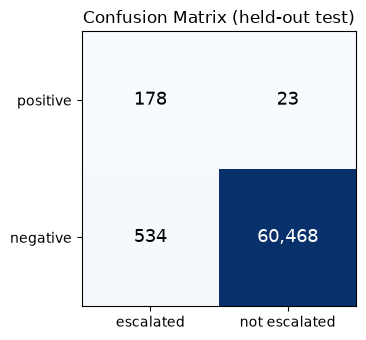

In [11]:
import matplotlib.pyplot as plt

pred = pd.read_csv(P.OUT / "system_predictions.csv")
y = pred["label"].astype(int); p = pred["escalate"].astype(int)
cm = pd.crosstab(y, p, rownames=["actual"], colnames=["predicted"])
cm = cm.reindex(index=[1, 0], columns=[1, 0]).fillna(0).astype(int)
cm.index = ["positive", "negative"]; cm.columns = ["escalated", "not escalated"]

fig, ax = plt.subplots(figsize=(4.5, 3.5))
im = ax.imshow(cm.values, cmap="Blues")
ax.set_xticks([0, 1], cm.columns); ax.set_yticks([0, 1], cm.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm.values[i, j]:,}", ha="center", va="center", fontsize=13,
                color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
ax.set_title("Confusion Matrix (held-out test)")
plt.tight_layout(); plt.show()

## Section 10 — Tier 3 / Week-4 Integration

The frozen Week-4 Tier-3 outputs (712 cases, 0 retries, 0 fallbacks) are loaded and aligned
with the frozen Tier-2 escalations by **(user, day)** — never by row position.

In [12]:
triage = pd.read_csv(P.W4_TRIAGE_OUTPUTS)
grounding = pd.read_csv(P.W4_GROUNDING_RESULTS)

esc_keys = set(zip(escalated["user"].astype(int), escalated["day"].astype(int)))
tr_keys = set(zip(triage["user"].astype(int), triage["day"].astype(int)))

align = {
    "frozen Tier-2 escalations": len(esc_keys),
    "Tier-3 output rows": len(triage),
    "matched (user, day)": len(esc_keys & tr_keys),
    "duplicate IDs": int(triage.duplicated(["user", "day"]).sum()),
    "missing IDs": len(esc_keys - tr_keys),
    "extra IDs": len(tr_keys - esc_keys),
}
pd.Series(align, name="count").to_frame()
assert len(esc_keys & tr_keys) == 712 and len(esc_keys - tr_keys) == 0
print("Alignment verified: 712 / 712.")

Alignment verified: 712 / 712.


In [13]:
# two representative frozen Tier-3 outputs (no raw logs)
triage[["user", "day", "explanation", "severity_category", "recommended_action", "evidence_used"]].head(2)

,user,day,explanation,severity_category,recommended_action,evidence_used
0,9,365,HTTP content length is reduced (0th percentile...,high,soc_escalation,"[""HTTP_E1""]"
1,11,280,URL depth is reduced (0th percentile). Risk sc...,high,immediate_isolation,"[""HTTP_E1""]"


## Section 11 — Tier-3 Grounding Validation

Two validation criteria exist and are **deliberately not reconciled**:

* **Week-4 final grounding contract** (`grounding_results_final.csv`): structural —
  validates the *deterministically constructed, evidence-derived observations*.
  712/712 validated observations, 0 invalid evidence IDs, 0 invalid channels,
  0 invalid observations, 0 unsupported intent terms.
* **Week-5 strict validation** (re-running the canonical `GroundingValidator` on the
  frozen outputs): applies the validator to each case's constructed explanation.
  Result: **576/712 strict `grounding_valid`**; the 136 failures are all
  `feature_grounding_valid=False` — the frozen `evidence_used` field lists only the
  top-1 evidence while the explanation cites a different evidence feature (a Week-4
  structural artifact, not a hallucination: 0 invalid evidence IDs, 0 invalid channels,
  0 unsupported intent terms).

The distinction is documented in the code and in
`week4/final_llm_reasoning/outputs/week4_final_audit.md`: the 100% Week-4 metrics are
*structural* metrics of the deterministic evidence layer, not proof that 100% of Qwen's
natural-language explanations are semantically grounded. Both numbers are reported as-is.

In [14]:
grounding[["metric", "value"]].head(13)

,metric,value
0,n_cases,712
1,llm_calls,712
2,retries,0
3,fallbacks,0
4,fallback_reasons,{'': 712}
5,cases_with_validated_observations,712
6,validated_observation_rate,1.0
7,cases_with_validated_evidence_ids,712
8,validated_evidence_rate,1.0
9,invalid_evidence_ids_total,0


In [15]:
# Week-5 strict re-validation using the canonical validator (existing code path)
import sys
sys.path.insert(0, str(P.WEEK4_FINAL))
from week5.final_pipeline.evidence_builder import EvidenceBuilder, feature_cols_by_modality
from week5.final_pipeline.grounding_validator import GroundingValidator
import ast

cols_all = pd.read_pickle(str(P.DATA_DIR / "dayr4.2-percentile30.pkl")).columns.tolist()
builder = EvidenceBuilder(P.DATA_DIR / "dayr4.2-percentile30.pkl", feature_cols_by_modality(cols_all), top_k=3)
validator = GroundingValidator()

strict_ok = 0; n = 0; fail_reasons = {}
for _, c in triage.iterrows():
    t2row = escalated[(escalated["user"] == c["user"]) & (escalated["day"] == c["day"])]
    if len(t2row) == 0:
        continue
    ev = builder.build_evidence(t2row.iloc[0])
    try:
        eids = ast.literal_eval(c["evidence_used"]) if isinstance(c["evidence_used"], str) else c["evidence_used"]
    except Exception:
        eids = []
    v = validator.validate(ev, str(c["explanation"]), str(c["severity_category"]),
                           str(c["recommended_action"]), eids)
    n += 1
    if v["grounding_valid"]:
        strict_ok += 1
    else:
        for k in ("feature_grounding_valid", "channel_grounding_valid",
                  "evidence_id_valid", "numeric_grounding_valid"):
            if k in v and v[k] is False:
                fail_reasons[k] = fail_reasons.get(k, 0) + 1

print(f"Week-5 strict grounding_valid: {strict_ok}/{n} = {strict_ok/n:.3f}")
print(f"Failure reasons (among non-valid): {fail_reasons}")

Week-5 strict grounding_valid: 576/712 = 0.809
Failure reasons (among non-valid): {'feature_grounding_valid': 136}


## Section 12 — ACTUAL SHAP Analysis

Uses the **real** `shap` package (`shap.DeepExplainer` 0.52.0) — not gradient
attribution. All claims are derived from the existing SHAP artifacts
(`shap_attributions.csv`, `shap_sanity.csv`, `shap_meta.json`).

* Background: **training users only** (`meta.train_users`), 100 samples per modality, seed 42.
  Held-out test users are never used as background (verified in Section 5 via disjoint user sets).
* 712 escalated cases × 4 modalities = 2,848 (case, modality) explanations.

In [16]:
shap_meta = json.loads((P.OUT / "shap_meta.json").read_text())
pd.DataFrame({
    "SHAP method": [shap_meta["shap_method"]],
    "SHAP version": [shap_meta["shap_version"]],
    "Background source": [shap_meta["background_source"]],
    "Background size": [shap_meta["background_n"]],
    "Background seed": [shap_meta["background_seed"]],
    "Explained (case, modality)": [shap_meta["n_explained"]],
    "Attribution rows": [f"{shap_meta['n_attribution_rows']:,}"],
})

,SHAP method,SHAP version,Background source,Background size,Background seed,"Explained (case, modality)",Attribution rows
0,shap.DeepExplainer,0.52.0,training split only (meta.train_users),100,42,2848,"346,032"


In [17]:
attr = pd.read_csv(P.OUT / "shap_attributions.csv")
print(f"Attribution rows: {len(attr):,}")
print(f"Distinct cases:   {attr['case_id'].nunique()}")
print(f"Channels:         {sorted(attr['channel'].unique())}")
print(f"NaN values:       {attr[['shap_value', 'abs_shap_value']].isna().sum().sum()}")
print(f"Inf values:       {int((~np.isfinite(attr[['shap_value', 'abs_shap_value']])).any(axis=1).sum())}")
print(f"SHAP method col:  {attr['shap_method'].unique()}")
print(f"SHAP version col: {attr['shap_version'].unique()}")

# feature alignment: every attribution row's feature must exist in that modality's model feature_cols
feature_universe = set()
for m in P.CHANNELS:
    feature_universe |= set(bundle["feature_cols"][m])
unknown = attr[~attr["feature"].isin(feature_universe)]
print(f"Features not in any model feature_cols: {len(unknown)}")
assert len(unknown) == 0
print("Feature alignment verified: every SHAP feature is a canonical model feature.")

Attribution rows: 346,032
Distinct cases:   712
Channels:         ['email', 'file_device', 'http', 'logon']
NaN values:       0
Inf values:       0
SHAP method col:  ['shap.DeepExplainer']
SHAP version col: ['0.52.0']
Features not in any model feature_cols: 0
Feature alignment verified: every SHAP feature is a canonical model feature.


In [18]:
# example: top-5 SHAP features for one escalated case in the HTTP channel
ex = attr[(attr["case_id"] == attr["case_id"].iloc[0]) & (attr["channel"] == "http")].head(5)
ex[["case_id", "user_id", "date", "channel", "feature", "shap_value", "abs_shap_value", "direction", "rank"]]

,case_id,user_id,date,channel,feature,shap_value,abs_shap_value,direction,rank
0,9_365,9,365,http,n_http,4.702623,4.702623,positive,1
1,9_365,9,365,http,http_n-pc0,4.633389,4.633389,positive,2
2,9_365,9,365,http,workhourhttp_otherf_mean_url_depth,-0.480050,0.480050,negative,3
3,9_365,9,365,http,http_mean_url_depth,-0.443703,0.443703,negative,4
4,9_365,9,365,http,http_otherf_mean_url_depth,-0.399601,0.399601,negative,5


## Section 13 — SHAP Additivity / Sanity

Loads `outputs/shap_sanity.csv` and programmatically checks
`model_output ≈ expected_value + sum(SHAP)` on the pre-sigmoid logit (tolerance 1e-3).

In [19]:
sanity = pd.read_csv(P.OUT / "shap_sanity.csv")
print(f"Explained:      {len(sanity):,}")
print(f"Passing:        {int(sanity['pass'].sum()):,}")
print(f"Failing:        {int((~sanity['pass']).sum()):,}")
print(f"Max residual:   {sanity['residual'].max():.3e}")
print(f"Mean residual:  {sanity['residual'].mean():.3e}")

# independent recomputation of the tolerance check on the logit scale
recomputed = (sanity["logit"] - (sanity["expected_value"] + sanity["sum_shap"])).abs() <= 1e-3
print(f"Recomputed additivity pass: {int(recomputed.sum())}/{len(sanity)}")
assert recomputed.all()
print("Additivity verified: logit ≈ expected_value + sum(SHAP) for all (case, modality).")

Explained:      2,848
Passing:        2,848
Failing:        0
Max residual:   1.881e-05
Mean residual:  5.399e-07
Recomputed additivity pass: 2848/2848
Additivity verified: logit ≈ expected_value + sum(SHAP) for all (case, modality).


## Section 14 — SHAP vs LLM Explanation Comparison

Loads `outputs/explanation_comparison.csv` + `explanation_comparison_summary.json`.

The comparison uses a **three-way claim classification** so a valid Week-4
evidence-grounded claim is never automatically "unsupported" merely because it is not in
the SHAP top-k:

1. **Supported by SHAP / top attribution** — mentioned AND in the per-channel SHAP top-k.
2. **Supported by canonical Week-4 evidence but not SHAP top-k** — mentioned AND in the
   evidence inventory (feature_deltas) but not in SHAP top-k. *Category 2 is a grounded,
   valid claim — it must NOT be classified as a hallucination*, because the LLM was shown
   the evidence inventory, not the SHAP ranking.
3. **Unsupported** — mentioned but supported by neither SHAP nor the canonical evidence.

SHAP `rank` is per (case, channel); the models' non-behavioral org metadata columns
(CERT r4.2 org codes O/C/E/A/N) are excluded from the comparison set because the LLM is
never shown them. The comparison methodology is unchanged.

In [20]:
cmp = pd.read_csv(P.OUT / "explanation_comparison.csv")
cmp_summary = json.loads((P.OUT / "explanation_comparison_summary.json").read_text())
print(f"Compared cases: {cmp_summary['n_cases']}")

pd.DataFrame({
    "Metric": ["Channel precision", "Channel recall", "Channel F1",
               "Feature precision", "Feature recall", "Feature F1",
               "Channel Jaccard (mean)", "Channel Jaccard (median)",
               "Feature Jaccard (mean)", "Feature Jaccard (median)",
               "Total LLM feature claims", "Supported by SHAP",
               "Evidence-grounded only", "Unsupported claims",
               "Unsupported claim rate", "Supported claim rate"],
    "Value": [f"{cmp_summary['channel_precision']:.4f}", f"{cmp_summary['channel_recall']:.4f}",
              f"{cmp_summary['channel_f1']:.4f}", f"{cmp_summary['feature_precision']:.4f}",
              f"{cmp_summary['feature_recall']:.4f}", f"{cmp_summary['feature_f1']:.4f}",
              f"{cmp_summary['channel_jaccard_mean']:.4f}", f"{cmp_summary['channel_jaccard_median']:.4f}",
              f"{cmp_summary['feature_jaccard_mean']:.4f}", f"{cmp_summary['feature_jaccard_median']:.4f}",
              f"{cmp_summary['total_llm_feature_claims']:,}", f"{cmp_summary['supported_by_shap_claims']:,}",
              f"{cmp_summary['evidence_grounded_only_claims']:,}", f"{cmp_summary['unsupported_claims']:,}",
              f"{cmp_summary['unsupported_claim_rate']:.4f}", f"{cmp_summary['supported_claim_rate']:.4f}"],
})

Compared cases: 712


,Metric,Value
0,Channel precision,1.0000
1,Channel recall,0.2803
2,Channel F1,0.4332
3,Feature precision,0.1014
4,Feature recall,0.0092
5,Feature F1,0.0166
6,Channel Jaccard (mean),0.2803
7,Channel Jaccard (median),0.2500
8,Feature Jaccard (mean),0.0090
9,Feature Jaccard (median),0.0000


In [21]:
# distribution of the three claim categories per case (small sample)
cat = cmp[["case_id", "supported_by_shap_features", "evidence_grounded_only_features", "unsupported_features"]].copy()
cat["n_supported_by_shap"] = cat["supported_by_shap_features"].apply(lambda x: len(eval(x)) if isinstance(x, str) else 0)
cat["n_evidence_grounded_only"] = cat["evidence_grounded_only_features"].apply(lambda x: len(eval(x)) if isinstance(x, str) else 0)
cat["n_unsupported"] = cat["unsupported_features"].apply(lambda x: len(eval(x)) if isinstance(x, str) else 0)
cat[["case_id", "n_supported_by_shap", "n_evidence_grounded_only", "n_unsupported"]].head(8)

,case_id,n_supported_by_shap,n_evidence_grounded_only,n_unsupported
0,9_365,0,1,0
1,11_280,0,1,0
2,11_486,0,1,0
3,11_487,0,1,0
4,49_37,0,2,0
5,49_39,0,3,0
6,49_42,0,1,0
7,49_44,0,1,0


## Section 15 — Graceful Degradation

Loads `outputs/degradation_results.csv` (leave-one-channel-out). The load-bearing channel
is identified from the actual results, not assumed.

In [22]:
deg = pd.read_csv(P.OUT / "degradation_results.csv")
deg[["config", "missing", "recall", "precision", "fpr", "f1", "roc_auc", "pr_auc", "escalated"]].round(4)

,config,missing,recall,precision,fpr,f1,roc_auc,pr_auc,escalated
0,all_channels,none,0.8856,0.2500,0.0088,0.3899,0.9829,0.5878,712
1,missing_http,http,0.6667,0.0245,0.0876,0.0472,0.8814,0.0874,5480
2,missing_file_device,file_device,0.8657,0.3000,0.0067,0.4456,0.9668,0.5065,580
3,missing_logon,logon,0.8905,0.2828,0.0074,0.4293,0.9850,0.6030,633
4,missing_email,email,0.8706,0.2210,0.0101,0.3525,0.9783,0.5491,792


In [23]:
base = deg[deg["missing"] == "none"].iloc[0]
rows = []
for _, r in deg[deg["missing"] != "none"].iterrows():
    rows.append({"missing": r["missing"],
                 "recall_delta": round(base["recall"] - r["recall"], 4),
                 "effect": "LOAD-BEARING" if (base["recall"] - r["recall"]) > 0.05 else "well-absorbed"})
pd.DataFrame(rows)

load_bearing = [r["missing"] for _, r in deg[deg["missing"] != "none"].iterrows()
                if (base["recall"] - r["recall"]) > 0.05]
print(f"Load-bearing channel(s) per actual results: {load_bearing or 'none'}")

Load-bearing channel(s) per actual results: ['http']


## Section 16 — FastAPI Demonstration

Uses the existing FastAPI application (`app.py`) via `TestClient`. A missing channel
degrades gracefully (weight renormalization — the missing score is never fabricated).

In [24]:
from fastapi.testclient import TestClient
from week5.final_pipeline.app import app

with TestClient(app) as client:
    h = client.get("/health").json()
    print("GET /health ->", h["status"], "| models_loaded:", h["models_loaded"],
          "| ollama:", h["ollama_available"])
    print("tier2_config:", h["tier2_config"])

    r = client.post("/score", json={
        "user": 9, "day": 365,
        "channel_scores": {"http_score": 0.93482506, "file_device_score": 0.007847345,
                           "logon_score": 0.0761948, "email_score": 0.21464822},
        "include_triage": True,
    })
    body = r.json()
    print("POST /score status:", r.status_code)
    print("tier2.fused_score:", round(body["tier2"]["fused_score"], 4),
          "| escalated:", body["tier2"]["escalated"],
          "| gate:", body["tier2"]["gate"],
          "| fired_channels:", body["tier2"]["fired_channels"])
    if body.get("tier3"):
        print("tier3.severity_category:", body["tier3"]["severity_category"],
              "| recommended_action:", body["tier3"]["recommended_action"])
        print("tier3.evidence_used:", body["tier3"]["evidence_used"])
        print("tier3.explanation:", (body["tier3"]["explanation"] or "")[:120])
    print("degraded_channels:", body["tier2"]["degraded_channels"],
          "| degraded_mode:", body["tier2"]["degraded_mode"])
    print("grounding:", body.get("grounding_validation", {}).get("grounding_valid"))

C:\insider_threat_detection_project2\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


[startup] Tier-3 pipeline ready | ollama: True
GET /health -> ok | models_loaded: True | ollama: True
tier2_config: {'hc_threshold': 0.6, 'corr_threshold': 0.3, 'weights': {'http': 0.5, 'file_device': 0.2, 'logon': 0.15, 'email': 0.15}}
POST /score status: 200
tier2.fused_score: 0.5126 | escalated: True | gate: high_confidence | fired_channels: ['http']
tier3.severity_category: high | recommended_action: soc_escalation
tier3.evidence_used: ['HTTP_E1']
tier3.explanation: HTTP content length is reduced (0th percentile). Risk score 0.513 triggered the high_confidence gate.
degraded_channels: [] | degraded_mode: False
grounding: True


In [25]:
# missing-channel demonstration (HTTP absent) — must not crash
with TestClient(app) as client:
    r = client.post("/score", json={
        "user": 5, "day": 37,
        "channel_scores": {"file_device_score": 0.9, "logon_score": 0.3, "email_score": 0.2},
        "include_triage": False,
    })
    b = r.json()
    print("status:", r.status_code,
          "| degraded_channels:", b["tier2"]["degraded_channels"],
          "| degraded_mode:", b["tier2"]["degraded_mode"],
          "| escalated:", b["tier2"]["escalated"])
    print("rationale:", b["tier2"]["rationale"][:150])

[startup] Tier-3 pipeline ready | ollama: True
status: 200 | degraded_channels: ['http'] | degraded_mode: True | escalated: True
rationale: DEGRADED MODE: channel(s) http unavailable; weights renormalized over remaining channels. Gate: correlation (risk 0.510).


## Section 17 — API Test Results

Loaded from the existing `outputs/api_test_results.json` (real measured latencies).

In [26]:
api = json.loads((P.OUT / "api_test_results.json").read_text())
tests = api["tests"]

rows = []
for k, v in tests.items():
    status = v.get("status")
    extra = ""
    if k == "missing_channel":
        extra = f" degraded={v.get('degraded_channels')} mode={v.get('degraded_mode')}"
    elif k == "graph_vectorized_equivalence":
        extra = f" n={v.get('n_compared')} mismatches={v.get('mismatches')}"
    rows.append({"test": k, "status": status, "detail": extra.strip()})
pd.DataFrame(rows)

,test,status,detail
0,health,200.0,
1,escalated,200.0,
2,non_escalated,200.0,
3,missing_channel,200.0,degraded=['http'] mode=True
4,malformed,422.0,
5,schema_invalid_range,422.0,
6,graph_vectorized_equivalence,NaN,n=200 mismatches=0


In [27]:
lat = api["latency_ms"]
print(f"GET /health latency:            {lat.get('health', 'n/a')} ms")
print(f"POST /score Tier1+Tier2 (mean): {lat.get('tier1_tier2_mean', 'n/a')} ms")
if api.get("tier3_latency_sample"):
    t3 = api["tier3_latency_sample"]
    print(f"POST /score Tier1+Tier2+Ollama: {t3.get('tier3_ollama_latency_ms', 'n/a')} ms "
          f"(severity={t3.get('severity_category')}, action={t3.get('recommended_action')})")

GET /health latency:            2.089 ms
POST /score Tier1+Tier2 (mean): 1.849 ms
POST /score Tier1+Tier2+Ollama: 1082.441 ms (severity=high, action=soc_escalation)


## Section 18 — MLflow

Inspects the **already-finished** Week-5 MLflow run (no new run is created for
presentation).

In [28]:
from mlflow.tracking import MlflowClient
import mlflow
# point at the local SQLite tracking store where the Week-5 run was logged
mlflow.set_tracking_uri("sqlite:///" + str(ROOT / "mlflow.db").replace("\\", "/"))
client = MlflowClient()
exp = client.get_experiment_by_name("week5_final_pipeline")
runs = client.search_runs([exp.experiment_id]) if exp else []

if runs:
    r = runs[0]
    print(f"Experiment: {exp.name}  (id {exp.experiment_id})")
    print(f"Run ID:     {r.info.run_id}")
    print(f"Status:     {r.info.status}")
    print(f"Parameters: {len(r.data.params)}   Metrics: {len(r.data.metrics)}")
    print("Artifacts (from mlruns/): system_metrics.csv, system_predictions.csv, "
          "shap_attributions.csv, explanation_comparison.csv, degradation_results.csv, "
          "final_week5_summary.json, shap_meta.json, shap_sanity.csv")
    key_metrics = {k: r.data.metrics[k] for k in
                   ("recall", "precision", "f1", "fpr", "roc_auc", "pr_auc",
                    "escalation_rate", "unsupported_claim_rate", "supported_claim_rate")
                   if k in r.data.metrics}
    pd.DataFrame(list(key_metrics.items()), columns=["metric", "value"]).round(4)
else:
    print("No Week-5 MLflow run found — tracking was not executed on this machine.")

Experiment: week5_final_pipeline  (id 12)
Run ID:     97bbb7574a454c21b2f62a1d2b9ebe77
Status:     FINISHED
Parameters: 14   Metrics: 23
Artifacts (from mlruns/): system_metrics.csv, system_predictions.csv, shap_attributions.csv, explanation_comparison.csv, degradation_results.csv, final_week5_summary.json, shap_meta.json, shap_sanity.csv


## Section 19 — Final Results Dashboard

All values are derived from the artifacts / executions above — nothing is hard-coded.

In [29]:
def _api_ok(api):
    """Honest API-test summary: 200s are passes, expected 422s (malformed/schema)
    are contract-passing rejections, equivalence is pass iff 0 mismatches."""
    t = api["tests"]
    ok = 0; total = 0
    for k, v in t.items():
        if k == "graph_vectorized_equivalence":
            total += 1; ok += int(v.get("mismatches", -1) == 0)
            continue
        total += 1
        st = v.get("status")
        ok += int(st == 200 or st == 422)  # 422 = correct rejection of bad input
    return f"{ok}/{total} ok (incl. expected 422 rejections)"

shap_ok = shap_meta["n_pass"] == shap_meta["n_explained"]
dash = pd.DataFrame({
    "Area": ["Tier-2 configuration", "Test rows", "Escalations", "Recall", "Precision",
             "F1", "FPR", "ROC-AUC", "PR-AUC", "SHAP", "SHAP sanity",
             "API tests", "Degradation", "MLflow"],
    "Result": ["Frozen (HC 0.60 / corr 0.30 / 50-20-15-15)",
               f"{sys_m['tier2_n_rows']:,}", f"{sys_m['tier2_escalated']:,}",
               f"{sys_m['tier2_recall']:.4f}", f"{sys_m['tier2_precision']:.4f}",
               f"{sys_m['tier2_f1']:.4f}", f"{sys_m['tier2_fpr']:.4f}",
               f"{sys_m['tier2_roc_auc']:.4f}", f"{sys_m['tier2_pr_auc']:.4f}",
               f"actual SHAP ({shap_meta['shap_method']} {shap_meta['shap_version']})",
               f"{shap_meta['n_pass']}/{shap_meta['n_explained']} additivity pass",
               _api_ok(api),
               f"load-bearing: {load_bearing or 'none'}",
               ("logged (run " + runs[0].info.run_id[:8] + ")") if runs else "not found"],
})
dash

,Area,Result
0,Tier-2 configuration,Frozen (HC 0.60 / corr 0.30 / 50-20-15-15)
1,Test rows,"61,203.0"
2,Escalations,712.0
3,Recall,0.8856
4,Precision,0.2500
5,F1,0.3899
6,FPR,0.0088
7,ROC-AUC,0.9829
8,PR-AUC,0.5878
9,SHAP,actual SHAP (shap.DeepExplainer 0.52.0)


## Section 20 — Limitations

1. **SHAP environment split** — `shap` 0.52.0 requires `numba` → numpy ≤ 2.4, which is
   incompatible with the frozen project venv (numpy 2.5.1). Real SHAP therefore runs in an
   isolated sandbox venv (`.venv-shap`); the frozen project environment is untouched.
2. **Week-4 vs Week-5 grounding criteria differ** — Week-4's 712/712 grounding metrics are
   *structural* (validate the deterministic evidence-derived observations); the stricter
   Week-5 validation on the constructed explanations yields 576/712 strict
   `grounding_valid`, all failures being the `evidence_used` top-1 vs explanation top-3
   artifact (0 invalid evidence IDs / channels / unsupported intent terms). The two
   criteria are reported as-is and are not reconciled.
3. **Feature-level SHAP/LLM overlap is low** (feature Jaccard mean ≈ 0.009) — the frozen
   Tier-3 explanation cites the canonical evidence inventory, which is not the same ranking
   as SHAP per-channel top-k; the comparison separates evidence-grounded-only claims so
   none are counted as unsupported.
4. **Qwen2.5-1.5B severity is coarse** (666/712 escalated labelled `high`) — a documented
   Week-4 limitation; Tier-3 has no manual severity/action policy and Qwen's values are
   preserved.
5. **HTTP is load-bearing** under channel-loss testing (recall drops when HTTP is missing).
6. **Tier 2 is intentionally recall-oriented**, so precision is lower (0.25) — it favours
   catching insider activity over minimising false alarms; Tier-3 then triages the
   escalated cases.

## Section 21 — Final Conclusion

This notebook demonstrates the finalized Week-5 system:

```
Tier 1 → Tier 2 → Tier 3 → FastAPI
```

* the held-out test split is **leakage-free** (train/val/test user sets disjoint);
* **Tier 2 remains frozen** (HC 0.60, correlation 0.30, weights 50/20/15/15) and makes
  the escalation decision;
* **Tier 3 does not make the security escalation decision** — it reasons only about
  escalated cases and preserves Qwen's severity/action;
* **actual SHAP** is used (`shap.DeepExplainer` 0.52.0) with **training-only background**
  data (100 samples/modality, seed 42) and verified additivity;
* degradation behavior is tested (HTTP is load-bearing; missing channels degrade
  gracefully without fabricated scores);
* API behavior is tested (`/health`, `/score`, missing channel, malformed/schema, latency);
* MLflow tracking exists (experiment `week5_final_pipeline`, run FINISHED);
* **Week 1–4 sources remain untouched**; nothing was retrained and the frozen 712
  Tier-3 outputs were not regenerated.